In [ ]:
# ===== Célula 1 — Carregar as avaliações =====
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Acha a raiz do projeto, esteja o notebook rodando de notebooks/ ou da raiz
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = RAIZ / "data" / "raw"

reviews = pd.read_csv(RAW / "olist_order_reviews_dataset.csv", encoding="utf-8-sig")

print(reviews.shape)
reviews.info()
reviews.head()

(99224, 7)
<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   review_id                99224 non-null  str  
 1   order_id                 99224 non-null  str  
 2   review_score             99224 non-null  int64
 3   review_comment_title     11568 non-null  str  
 4   review_comment_message   40977 non-null  str  
 5   review_creation_date     99224 non-null  str  
 6   review_answer_timestamp  99224 non-null  str  
dtypes: int64(1), str(6)
memory usage: 17.8 MB


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela Internet seguro e prático Parabéns a todos feliz Páscoa,2018-03-01 00:00:00,2018-03-02 10:26:53


In [ ]:
# ===== Célula 2 — Quantas avaliações têm texto? =====

# "Tem texto" = não é nulo E não é só espaço em branco
titulo = reviews["review_comment_title"].fillna("").str.strip()
mensagem = reviews["review_comment_message"].fillna("").str.strip()
tem_titulo = titulo != ""
tem_msg = mensagem != ""

presenca = pd.DataFrame({
    "situação": ["só título", "só mensagem", "título e mensagem", "nenhum texto"],
    "avaliações": [
        (tem_titulo & ~tem_msg).sum(),
        (~tem_titulo & tem_msg).sum(),
        (tem_titulo & tem_msg).sum(),
        (~tem_titulo & ~tem_msg).sum(),
    ],
})
presenca["%"] = (presenca["avaliações"] / len(reviews) * 100).round(1)
presenca

,situação,avaliações,%
0,só título,1737,1.8
1,só mensagem,31121,31.4
2,título e mensagem,9829,9.9
3,nenhum texto,56537,57.0


In [ ]:
# ===== Célula 3 — Avaliações repetidas =====

dup = reviews[reviews.duplicated("review_id", keep=False)].sort_values("review_id")
print(f"{dup['review_id'].nunique():,} review_ids aparecem em {len(dup):,} linhas")

# Para cada review_id repetido: quantos valores DIFERENTES existem em cada coluna?
# Se der 1 em tudo, menos order_id, é a MESMA avaliação ligada a pedidos diferentes
colunas = ["order_id", "review_score", "review_comment_title",
           "review_comment_message", "review_creation_date"]
print("\nMáximo de valores distintos por review_id repetido:")
print(dup.groupby("review_id")[colunas].nunique(dropna=False).max())

# O caso inverso: um mesmo pedido com mais de uma avaliação
print(f"\nPedidos com mais de uma avaliação: {reviews['order_id'].duplicated().sum():,}")

dup.head(6)

789 review_ids aparecem em 1,603 linhas

Máximo de valores distintos por review_id repetido:
order_id                  3
review_score              1
review_comment_title      1
review_comment_message    1
review_creation_date      1
dtype: int64

Pedidos com mais de uma avaliação: 551


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53


In [4]:
# ===== Célula 4 — Notas e "quem escreve" =====
unicas = reviews.drop_duplicates("review_id").copy()
unicas["tem_texto"] = (
    unicas["review_comment_title"].fillna("").str.strip().ne("")
    | unicas["review_comment_message"].fillna("").str.strip().ne("")
)

por_nota = unicas.groupby("review_score").agg(
    avaliacoes=("review_id", "size"),
    pct_com_texto=("tem_texto", "mean"),
)
por_nota["pct_do_total"] = (por_nota["avaliacoes"] / por_nota["avaliacoes"].sum() * 100).round(1)
por_nota["pct_com_texto"] = (por_nota["pct_com_texto"] * 100).round(1)
por_nota

,avaliacoes,pct_com_texto,pct_do_total
review_score,,,
1,11282,77.3,11.5
2,3114,68.7,3.2
3,8097,44.6,8.2
4,19007,32.8,19.3
5,56910,38.1,57.8


Avaliações com texto: 42,370
count    42370.0
mean        11.7
std          9.7
min          0.0
10%          2.0
25%          4.0
50%          9.0
75%         16.0
90%         28.0
99%         38.0
max         48.0
Name: palavras, dtype: float64


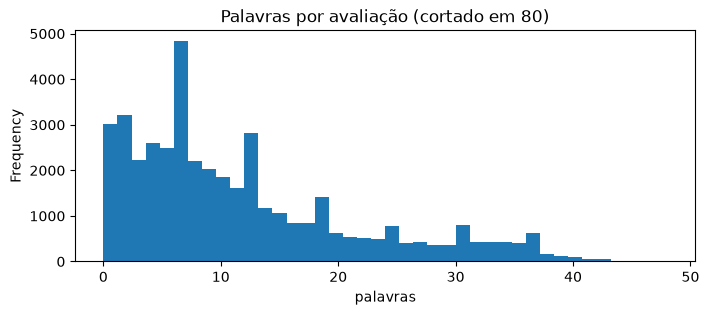

In [5]:
# ===== Célula 5 — Tamanho dos textos =====
com_texto = unicas[unicas["tem_texto"]].copy()
t = com_texto["review_comment_title"].fillna("").str.strip()
m = com_texto["review_comment_message"].fillna("").str.strip()
# Junta título e mensagem; strip(". ") limpa o ". " que sobra quando um dos dois está vazio
com_texto["texto"] = (t + ". " + m).str.strip(". ")
com_texto["palavras"] = com_texto["texto"].str.split().str.len()

print(f"Avaliações com texto: {len(com_texto):,}")
print(com_texto["palavras"].describe(percentiles=[.1, .25, .5, .75, .9, .99]).round(1))

com_texto["palavras"].clip(upper=80).plot.hist(bins=40, figsize=(8, 3),
    title="Palavras por avaliação (cortado em 80)")
plt.xlabel("palavras"); plt.show()

In [6]:
# ===== Célula 6 — Textos curtos e repetitivos =====
print("Avaliações com até 2 palavras:", (com_texto["palavras"] <= 2).sum())
print("\nOs 25 textos mais repetidos:")
com_texto["texto"].str.lower().value_counts().head(25)

Avaliações com até 2 palavras: 6232

Os 25 textos mais repetidos:


texto
muito bom                501
bom                      388
recomendo                385
ótimo                    276
otimo                    241
excelente                232
super recomendo          140
ok                       126
boa                      116
tudo ok                   97
ótimo produto             94
                          77
não recebi o produto      76
gostei                    71
ótima                     71
bom produto               62
tudo certo                61
10                        54
entrega rápida            51
gostei muito              48
chegou antes do prazo     48
otima                     44
muito boa                 42
adorei                    41
perfeito                  40
Name: count, dtype: int64

In [7]:
# ===== Célula 7 — Casas de Game of Thrones (nomes anonimizados) =====
casas = ["stark", "lannister", "targaryen", "baratheon", "greyjoy", "tyrell",
         "martell", "arryn", "tully", "bolton", "frey", "mormont"]
padrao = r"\b(" + "|".join(casas) + r")\b"  # \b = palavra inteira

achado = com_texto["texto"].str.lower().str.extract(padrao, expand=False)
print(f"Avaliações citando alguma casa: {achado.notna().sum():,}")
print(achado.value_counts())

# Alguns exemplos para ver o contexto em que aparecem
com_texto.loc[achado.notna(), ["review_score", "texto"]].head(8)

Avaliações citando alguma casa: 1,951
texto
lannister    1177
stark         292
baratheon     269
targaryen     213
Name: count, dtype: int64


,review_score,texto
4,5,Parabéns lojas lannister adorei comprar pela I...
32,1,Sempre compro pela Internet e a entrega ocorre...
115,1,Este foi o pedido\r\nBalde Com 128 Peças - Blo...
151,5,Sempre compro na lannister.Pra mim é a melhor ...
170,5,"prazo entrega. Espero receber esta semana, o q..."
180,3,"Comprei dois lustres pendentes, com a parceira..."
227,3,Não recomendaria esta loja nem pretendo voltar...
239,1,"Demora na entrega, detestei o atendimento e NU..."


In [8]:
# ===== Célula 8 — Ler os dados com os olhos =====
pd.set_option("display.max_colwidth", 200)  # mostra textos inteiros, sem cortar
(com_texto.groupby("review_score", group_keys=False)
          .sample(3, random_state=42)[["review_score", "texto"]])

,review_score,texto
6955,1,Produto de qualidade ruim. Produto diferente do que foi anunciado
68490,1,não recebi meu produto quero meu dinheiro de volta
91069,1,"Comprei um produto e recebi outro. Estou tentando contato com o fornecedor, porém até o momento não tive retorno"
62422,2,Só achei elas bem fraquinhas mesmo com o preço baixo achei que se tratava de uma promoção e não de toalhas pequenas e frágeis
50701,2,"Super enrolado.. transporte desatualizado, e fora do prazo. Mais de 30 dias esperando"
30731,2,"Faltou mercadoria. Só veio um dos pendentes , preciso dos outros, conforme a nota"
89923,3,ok! muito bonito
36706,3,"Não recebi meu tapete, mas está marcando como entregue"
81448,3,O produto veio estourado
52480,4,"Ótimo material, entregue no prazo... perfeito... obrigado"


In [10]:
# ===== Célula 9 — Carregar as demais tabelas =====
import numpy as np

datas = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
         "order_delivered_customer_date", "order_estimated_delivery_date"]
orders = pd.read_csv(RAW / "olist_orders_dataset.csv", encoding="utf-8-sig", parse_dates=datas)
items = pd.read_csv(RAW / "olist_order_items_dataset.csv", encoding="utf-8-sig")
products = pd.read_csv(RAW / "olist_products_dataset.csv", encoding="utf-8-sig")
traducao = pd.read_csv(RAW / "product_category_name_translation.csv", encoding="utf-8-sig")
customers = pd.read_csv(RAW / "olist_customers_dataset.csv", encoding="utf-8-sig")

# Tabela-ponte: cada par (avaliação, pedido) uma única vez
rev_ped = reviews[["review_id", "order_id"]].drop_duplicates()

print("Status dos pedidos:")
print(orders["order_status"].value_counts())
print("\nDatas ausentes por coluna:")
print(orders[datas].isna().sum())

Status dos pedidos:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Datas ausentes por coluna:
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [11]:
# ===== Célula 10 — Situação da entrega e relação com a nota =====
# Atraso = data real de entrega - data prometida (em dias; positivo = atrasou)
orders["dias_atraso"] = (orders["order_delivered_customer_date"].dt.normalize()
                         - orders["order_estimated_delivery_date"].dt.normalize()).dt.days
orders["situacao_entrega"] = np.select(
    [orders["order_delivered_customer_date"].isna(), orders["dias_atraso"] > 0],
    ["não entregue", "atrasado"],
    default="no prazo",
)

# Por avaliação: vale o PIOR caso entre os pedidos ligados (não entregue > atrasado > no prazo)
gravidade = {"no prazo": 0, "atrasado": 1, "não entregue": 2}
entrega_rev = (rev_ped.merge(orders[["order_id", "situacao_entrega", "dias_atraso"]], on="order_id")
               .assign(grav=lambda d: d["situacao_entrega"].map(gravidade))
               .sort_values("grav")
               .groupby("review_id")
               .agg(situacao_entrega=("situacao_entrega", "last"),
                    dias_atraso=("dias_atraso", "max")))

base = unicas.set_index("review_id").join(entrega_rev)
print(base["situacao_entrega"].value_counts(normalize=True).mul(100).round(1))
print("\nNota média por situação da entrega:")
print(base.groupby("situacao_entrega")["review_score"].agg(["mean", "size"]).round(2))
print("\nDistribuição das notas (%) por situação:")
pd.crosstab(base["situacao_entrega"], base["review_score"], normalize="index").mul(100).round(1)

situacao_entrega
no prazo        90.6
atrasado         6.5
não entregue     2.9
Name: proportion, dtype: float64

Nota média por situação da entrega:
                  mean   size
situacao_entrega             
atrasado          2.27   6384
no prazo          4.29  89178
não entregue      1.76   2848

Distribuição das notas (%) por situação:


review_score,1,2,3,4,5
situacao_entrega,,,,,
atrasado,53.7,8.6,10.9,10.2,16.6
no prazo,6.6,2.6,8.1,20.4,62.3
não entregue,70.4,7.3,7.5,5.4,9.3


In [12]:
# ===== Célula 11 — Categorias dos produtos =====
itens_cat = (items[["order_id", "product_id", "price"]]
             .merge(products[["product_id", "product_category_name"]], on="product_id", how="left")
             .merge(traducao, on="product_category_name", how="left"))

print("Itens sem categoria:", itens_cat["product_category_name"].isna().sum())
sem_traducao = itens_cat.loc[itens_cat["product_category_name"].notna()
                             & itens_cat["product_category_name_english"].isna(),
                             "product_category_name"].value_counts()
print("\nCategorias sem tradução:\n", sem_traducao)

# Quantas categorias DIFERENTES cada avaliação toca (somando todos os pedidos ligados)?
cat_rev = rev_ped.merge(itens_cat[["order_id", "product_category_name"]].drop_duplicates(),
                        on="order_id", how="left")
n_cat = cat_rev.groupby("review_id")["product_category_name"].nunique()
print("\nCategorias distintas por avaliação:")
print(n_cat.value_counts().sort_index())

print("\nTop 15 categorias entre as avaliações com texto:")
com_texto_ids = set(com_texto["review_id"])
(cat_rev[cat_rev["review_id"].isin(com_texto_ids)]
 .drop_duplicates(["review_id", "product_category_name"])
 ["product_category_name"].value_counts().head(15))

Itens sem categoria: 1603

Categorias sem tradução:
 product_category_name
portateis_cozinha_e_preparadores_de_alimentos    15
pc_gamer                                          9
Name: count, dtype: int64

Categorias distintas por avaliação:
product_category_name
0     2069
1    95378
2      939
3       24
Name: count, dtype: int64

Top 15 categorias entre as avaliações com texto:


product_category_name
cama_mesa_banho           4425
beleza_saude              3567
esporte_lazer             3063
informatica_acessorios    2813
moveis_decoracao          2672
relogios_presentes        2610
utilidades_domesticas     2520
telefonia                 1905
automotivo                1775
ferramentas_jardim        1625
cool_stuff                1559
brinquedos                1482
perfumaria                1284
bebes                     1106
eletronicos               1085
Name: count, dtype: int64

Primeira avaliação: 2016-10-02
Última avaliação:   2018-08-31


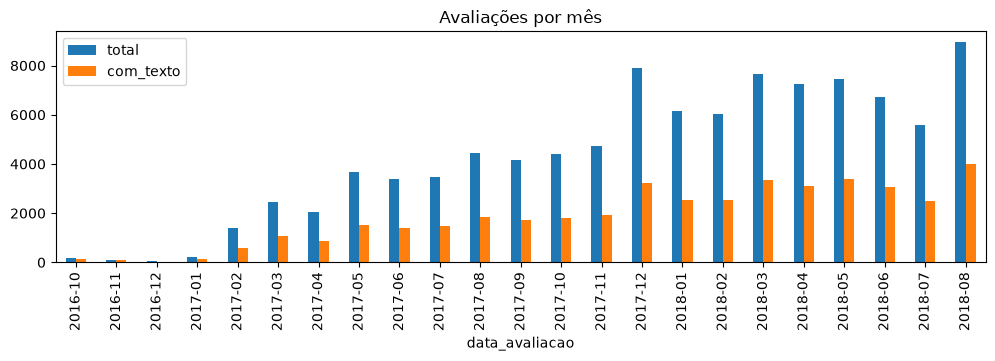

,total,com_texto
data_avaliacao,,
2016-10,176,121
2016-11,101,79
2016-12,45,35
2017-01,232,118
2017-02,1392,585
2017-03,2459,1086


In [13]:
# ===== Célula 12 — Período das avaliações =====
base["data_avaliacao"] = pd.to_datetime(base["review_creation_date"])
print("Primeira avaliação:", base["data_avaliacao"].min().date())
print("Última avaliação:  ", base["data_avaliacao"].max().date())

por_mes = base.groupby(base["data_avaliacao"].dt.to_period("M")).agg(
    total=("review_score", "size"), com_texto=("tem_texto", "sum"))
por_mes.plot.bar(figsize=(12, 3), title="Avaliações por mês")
plt.show()
por_mes.head(6)

In [14]:
# ===== Célula 13 — Estado (UF) do cliente =====
uf_rev = (rev_ped.merge(orders[["order_id", "customer_id"]], on="order_id")
          .merge(customers[["customer_id", "customer_state"]], on="customer_id")
          .groupby("review_id")["customer_state"].first())
base = base.join(uf_rev)

resumo_uf = base.groupby("customer_state").agg(
    avaliacoes=("review_score", "size"),
    nota_media=("review_score", "mean"),
    pct_atraso=("situacao_entrega", lambda s: (s == "atrasado").mean() * 100),
).round(1).sort_values("avaliacoes", ascending=False)
resumo_uf.head(10)

,avaliacoes,nota_media,pct_atraso
customer_state,,,
SP,41360,4.2,4.3
RJ,12647,3.9,11.5
MG,11526,4.1,4.4
RS,5430,4.1,5.9
PR,5004,4.2,3.9
SC,3600,4.1,7.9
BA,3332,3.9,11.6
DF,2120,4.1,5.6
ES,2006,4.0,10.2


In [15]:
# ===== Célula 14 — Conferir a base de conhecimento gerada =====
PROC = RAIZ / "data" / "processed"
corpus = pd.read_parquet(PROC / "corpus.parquet")
avaliacoes = pd.read_parquet(PROC / "avaliacoes.parquet")
print(f"avaliacoes.parquet: {len(avaliacoes):,} linhas | corpus.parquet: {len(corpus):,} linhas")

# Rastreabilidade: a reclamação do cartucho (ligada a 2 pedidos na célula 3) virou 1 documento só
print("\nFicha completa de um documento:")
print(corpus.loc[corpus["review_id"] == "00130cbe1f9d422698c812ed8ded1919"].T.to_string())

corpus.sample(5, random_state=42)

avaliacoes.parquet: 98,410 linhas | corpus.parquet: 42,251 linhas

Ficha completa de um documento:
                                                                                                                                                                                                         12904
review_id                                                                                                                                                                     00130cbe1f9d422698c812ed8ded1919
texto                O cartucho "original HP" 60XL não é reconhecido pela impressora, consequentemente não funcionou. Além de ter chegado com atraso de mais de 15 dias do previsto. Preciso que seja trocado.
nota                                                                                                                                                                                                         1
situacao_entrega                                                         

,review_id,texto,nota,situacao_entrega,dias_atraso,status_pedido,categoria_principal,categorias,data_compra,data_avaliacao,uf,regiao,empresas_citadas,n_palavras,texto_curto,chave_texto,pedidos
8021,fd722f7fa9682ea29f97eab06ed9a32b,Sou cliente da loja e sempre satisfeita com o atendimento e qualidade do servico,5,no prazo,-11,delivered,automotivo,automotivo,20170529,20170622,RJ,Sudeste,,14,False,sou cliente da loja e sempre satisfeita com o atendimento e qualidade do servico,db18c3a700202016c801626db03e7131
12959,f30f0034384b3a176508296ea0ab302c,"O produto apresenta riscos, aparência de usado, apesar de estar funcionando. O produto foi entregue em embalagem, porém envolto em papel bolha, não acondicionado em caixa.",3,no prazo,-11,delivered,eletronicos,eletronicos,20180203,20180225,MS,Centro-Oeste,,26,False,o produto apresenta riscos aparencia de usado apesar de estar funcionando o produto foi entregue em embalagem porem envolto em papel bolha nao acondicionado em caixa,48a928c553c276852b35ce90fedfeee2
41008,f2bf4a6225c02391ec9a909b558a96fd,Ótimo produto,5,no prazo,-8,delivered,ferramentas jardim,ferramentas jardim,20171211,20171228,SP,Sudeste,,2,True,otimo produto,053180cf4b0cf3f7a300e2e42ff01da9
41772,671026223a554a2e17f2bdd7f6df9fb1,"Solicito informações sobre a compra e o estorno da compra? Se o valor for devolvido, recomendaria a loja sim",2,atrasado,16,delivered,cama mesa banho,cama mesa banho,20171124,20171220,PR,Sul,,19,False,solicito informacoes sobre a compra e o estorno da compra se o valor for devolvido recomendaria a loja sim,f001d39de25ce801a4b275f5ad3e1c2e
7321,eb37b493f1df329bd53aca24032f9b77,"Sei que esse não e o canal ideal, estou ha dias tentando realizar esse cancelamento e não estou conseguindo. Recebi o produto, porém minha filha ganhou o mesmo produto do pai. Preciso cancelar.",4,no prazo,-44,delivered,brinquedos,brinquedos,20161009,20161019,SP,Sudeste,,33,False,sei que esse nao e o canal ideal estou ha dias tentando realizar esse cancelamento e nao estou conseguindo recebi o produto porem minha filha ganhou o mesmo produto do pai preciso cancelar,5c5c9fde60ffb741545cf2608e8c12ca
